# Sorbonne Université
## UE 3M236 Analyse Numérique des Equations Différentielles


## TP 6 : Des schémas implicites
  

In [3]:
import numpy as np # donne acces a la librairie numpy, et definit l'abbreviation np
import scipy        # donne acces aux librairies scipy, scipy.linalg et scipy.integrate
import scipy.linalg
import scipy.integrate
import matplotlib.pyplot as plt # donne acces a la librairie matplotlib.pyplot, et definit l'abbreviation plt
import math     # donne acces aux fonctions et constantes mathematiques
from math import exp
%matplotlib inline    
# ouvre les fenetres graphiques dans le notebook

### Exercice 1.
Considérons le problème
$$
\begin{cases}
\dot{y}(t) = -\lambda y + 1 + \lambda t \\
y(0) = 2
\end{cases}
$$
modélisant une réaction chimique. Dans ce type de phénomène, plusieurs échelles de temps cohabitent,
 certaines réactions étant très rapides,
tandis que d'autres sont très lentes. On parle de problèmes lents-rapides.
On fixera $T = 0.5$, $\lambda = 1000$.

#### Question 1.
La solution exacte est la fonction $y_e: [0, +\infty) \mapsto \mathbb R$, définie par
$$y_e(t) = t + 2e^{−λt},\quad \forall  t\in [0, +\infty).$$
Programmer une fonction $solexacte(t,y0,lam)$ renvoyant la valeur de la solution $y_e(t)$. Ensuite programmer la fonction du second membre, $f(y,t,\lambda)$. 

In [4]:
#votre solution ici:
def solexacte(t, y0):
    y_exa=t+y0*np.exp(-lam*t)
    
    return y_exa

def f(y,t):
    yprime=-lam*y+1+lam*t
    return yprime



#### Question 2:
Commencons par reprendre le schéma d'Euler Explicite. Vous avez vu en cours que ce schéma peut se définir à partir de la définition d'une dérivée.
$$ y'(t) \simeq \underset{h \rightarrow 0}{lim}\frac{y(t+h) - y(t)}{h} $$

En discrétisant l'intervalle d'étude $[t_0,t_0+T]$ en $N$ subdivisions de longueur $h=T/N$, on trouve, pour $t_n=t_0+nh$:
$$ y'(t_n) \simeq \frac{y(t_{n+1}) - y(t_n)}{h} $$
d'où on définit la suite des valeurs approchées
$$ \frac{y_{n+1} - y_n}{h} \simeq f(y_n,t_n) $$
Trouvez une expression pour $y_{n+1}$ à partir de cette dernière. 

Votre réponse ici: $y_{n+1} =y_n+hf(y_n,t_n) $

Vous avez trouvé l'expression d'Euler Explicite? Dans Larousse, le mot EXPLICITE designe ce qui est énoncé complètement. Effectivement, dans le schéma d'Euler Explicite, l'expression de $y_{n+1}$ est complètement énoncée en fonction de $y_{n}$, $t$, et $f$. 

#### Question 3. Schéma d'Euler Explicite
Calculer la solution approchée avec la méthode d’Euler explicite. Tracer-la sur le même graphique que la solution exacte. Trouver le nombre de pas de temps minimal pour que la solution numérique soit une "bonne approximation" de la solution exacte, visuellement.

In [7]:

def EulerExplicite(t0, x0, T, N, f):
    #N est le nombre de subdivisions de l'intervalle [t0,t0+T]
    h=T/N        
    TPS=np.arange(t0, T+t0, h)
    X=[x0]
    for i in range(len(TPS)-1):
        X.append(X[-1]+h*f(X[-1],TPS[i]))
    return TPS, np.array(X)

In [8]:
#alternative
def EulerExplicite(t0, x0, T, N, f):
    #N est le nombre de subdivisions de l'intervalle [t0,t0+T]
    h=T/N        
    TPS=np.linspace(t0, T+t0, N+1)
    X=[x0]
    for n in range(N):
        X.append(X[n]+h*f(X[n],TPS[n]))
    return TPS, np.array(X)

Text(0, 0.5, 'y')

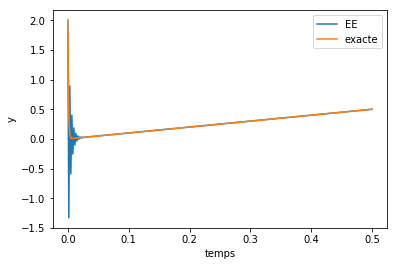

In [9]:
#tracer les solutions:
t0=0
T=0.5
y0=2
N=300
lam=1000.
TPS, solEE=EulerExplicite(t0, y0, T, N, f)
solEX=solexacte(TPS,y0)
plt.plot(TPS,solEE,label='EE')
plt.plot(TPS,solEX,label='exacte')
plt.legend()
plt.xlabel('temps')
plt.ylabel('y')


En tâtonnant, on voit qu'à partir de N=500 la solution numérique est comparable qualitativement avec la solution exacte. Pour des valeurs de N inférieures à 300 le schéma explose. 

Changer la valeur du parametre $\lambda=100$ et refaire l'expérience 

Text(0.5, 1.0, 'solutions exacte et approchée')

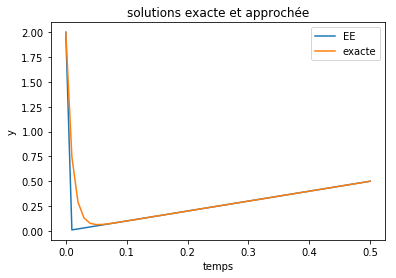

In [10]:
#tracer les solutions:
t0=0
T=0.5
y0=2
N=50
lam=100.
TPSEE, solEE=EulerExplicite(t0, y0, T, N, f)
solEX=solexacte(TPSEE,y0)
plt.plot(TPSEE,solEE,label='EE')
plt.plot(TPSEE,solEX,label='exacte')
plt.legend()
plt.xlabel('temps')
plt.ylabel('y')
plt.title('solutions exacte et approchée')


Même comportement pour cette valeur de $\lambda$ divisée par 10. Pour que la solution numérique ait l'allure de la solution exacte il faut que $N$  soit supérieur à $\lambda/2$ donc ici 50.

#### Question 4.
De la même façon que dans la question 2, on peut écrire:
\begin{equation}
f(y(t_{n+1}),t_{n+1}) \simeq \frac{y(t_{n+1}) - y(t_n)}{h}  
\end{equation}
et définir une suite de valeurs approchées
\begin{equation}
f(y_{n+1},t_{n+1}) = \frac{y_{n+1} - y_n}{h}  
\end{equation}

Résoudre cette équation pour $y_{n+1}$.

Votre réponse ici: $y_{n+1} = y_n+hf(y_{n+1},t_{n+1})$

Vous avez trouvé que $y_{n+1}$ dépend de lui-même? Maintenant, on a le schéma d'Euler Implicite. 

(Attention, si vous avez écrit $y_{n+1} = y_n + h f \big( y_n + h f(y_n, t_n), t_{n+1} \big)$, vous verrez que ceci ressemble au schéma d'Euler modifié, qui est explicite.)

Dans Larousse, le mot IMPLICITE designe ce qui, sans être énoncé formellement, découle naturellement de quelque chose. Effectivement, ce schéma découle naturellement, mais nous n'avons toujours pas d'expression explicite (praticable) pour $y_{n+1}$.

#### Question 5.
Comment trouver $y_{n+1}$ à partir de l'expression ci-dessus? On introduit la fonction $\ell$ telle que $$y_{n+1} = \ell (t_{n+1},y_{n+1}, y_{n}, f, h)=y_n+hf(y_{n+1},t_{n+1})$$

$y_{n+1}$ est donc une valeur annulant la fonction 


$$g(y,y_n,t_{n+1},h,f)=y-\ell (t_{n+1},y, y_n,   h,f)$$

Coder cette fonction $g(y,y_n,t_{n+1},h,f)$, en passant les paramètres nécessaires dans les arguments d'entrée. Elle nous servira pour calculer $y_{n+1}$ dans le schéma implicite. 

In [11]:
def g(y,yn,t,h,f):
    gy=y-yn-h*f(y,t)
    return gy

#### Question 6.
Calculer la solution approchée avec la méthode d’Euler implicite: 

Initialiser $y_0=y(t_0)$
Tant que $t<T$ faire :
<ul>
<li>$t_{n+1} = t_n + \Delta t$
<li>Résoudre l'équation Résoudre l'équation $g(y_{n+1},y_n,t_{n+1},f,h)=0$
 <li>$n=n+1$
 </ul>
 
 Vous vous servirez de la fonction $scipy.optimize.fsolve$ pour résoudre $g(y,t,dt,f) = 0$.


In [12]:
import scipy.optimize
def EulerImplicite(t0, x0, T, N, f):
    #...initialisation...
    h=T/N
    TPS=np.linspace(t0,t0+T,N+1)
    X=[x0]
    for n in range(N):
        args_g=X[n],TPS[n+1],h,f  #si la fonction g prend N>2 arguments, il faut passer les 2:N arguments dans un tableau.
        x_n1=scipy.optimize.fsolve(g,X[n],args=args_g)
        X.append(x_n1)
    return TPS, np.array(X)

51 51 1
2.0


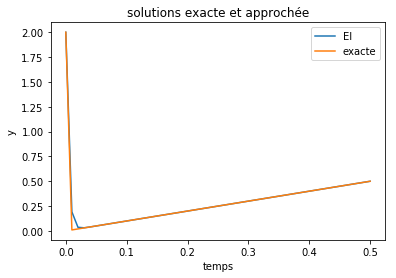

In [13]:
#tracer les solutions:
t0=0
T=0.5
y0=2
N=50
lam=1000.
TPS, solEI=EulerImplicite(t0, y0, T, N, f)
solEX=solexacte(TPS,y0)
plt.plot(TPS,solEI,label='EI')
plt.plot(TPS,solEX,label='exacte')
plt.legend()
plt.xlabel('temps')
plt.ylabel('y')
plt.title('solutions exacte et approchée')
V=solEI[1]-solEX
print(len(solEX),len(solEI),len(V.shape))
print(solEX[0])


Combien de pas de temps sont nécessaires pour obtenir une solution approchée satisfaisante ?


Avec 50 points seulement, la solution numérique est déjà proche de la solution exacte, et il n'y a pas de phénomène d'explosion comme avec le schéma explicite.

#### Question 7. 
Comparer les courbes de convergence.
Attention, ici, par rapport aux TP précédents, l'erreur maximale entre la solution exacte et la solution approchée n'est pas atteinte au temps finale, mais dans la partie initiale de la simulation. Il faut donc calculer l'erreur avec la formule de la définition : pour un schéma numérique calculant les approximations $\bar y_i\approx y(t_i)$ pour $i=0\ldots N$ l'erreur est définie par
$$
E_N=\max_{i=0,\ldots,N}|y(t_i)-\bar y_i|$$

In [14]:
def erreur(N,schema):
    #calcul de la solution approchée 
    t0=0
    T=0.5
    y0=2
    
    TPS, solNUM=schema(t0, y0, T, N, f)
    #calcul de la solution exacte
    solEX=solexacte(TPS,y0)
    #calcul de l'erreur
    diff=solNUM-solEX
    E=np.max(np.abs(diff))
    return E

/Volumes/USER/postel/anaconda3/lib/python3.7/site-packages/scipy/optimize/minpack.py:163: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


Text(0, 0.5, 'E')

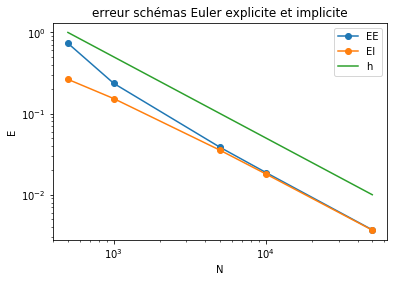

In [15]:
lam=1000
N_=[500,1000,5000,10000,50000]
E_EE=[]
E_EI=[]
for N in N_:
    E_EE.append(erreur(N,EulerExplicite))  
    E_EI.append(erreur(N,EulerImplicite))
plt.plot(N_,E_EE,'-o',label='EE')
plt.plot(N_,E_EI,'-o',label='EI')
plt.plot(N_,[1000*T/N for N in N_],label='h')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.title('erreur schémas Euler explicite et implicite')
plt.xlabel('N')
plt.ylabel('E')

### Exercice 2: Comment debugger votre code?


#### Question 1. Comprendre les dimensions d'un tableau

Commencons par le schéma Euler Explicite. Essayez le code ci-dessous sur un problème de l'exercice 2 du TP3. Avez-vous des erreurs? Si oui, vous avez peut-être un problème de dimension dans votre schéma...


In [16]:
a0=1.
a1=1.
T=4*np.pi
X2=np.array([a0,a1])
dt=0.5
t0 = 0
def f2(X,t):
    Y=np.asarray([X[1], -X[0]]) 
    return Y

TPS, XEE=EulerExplicite(0, X2, T, N, f2)


Prennons comme exemple la correction d'Euler Explicite du TP3. Remplir les commandes "print()" pour imprimer les dimensions des tableaux. Comment diffèrent les attribus len(), .shape, et np.size? Quelles informations nous donnent-ils sur les tableaux?

In [17]:
def EulerExplicite3(t0, x0, T, N, f):

    #exemples:
    print(x0.shape)
    print(np.size(x0))
    print(len(x0))
    
    if np.size(x0)==1: 
        x0=np.array([float(x0)])
        
    # initialisation
    TPS=[t0] 
    print(len(TPS)) #à remplir
    X=[x0] 
    print(len(X)) #à remplir
    dt=T/N
    for i in range(N):
        # calcul de ma solution au temps suivant
        t1=t0+dt
        test = f(x0,t0)
        print(test.shape) #à remplir et décommenter pour comprendre la dimension du retour de f
        x1=x0+dt*f(x0,t0)
        print(x1.shape) #à remplir et décommenter
        
        TPS=np.append(TPS,[t1])
        print(len(TPS)) #à remplir et décommenter
        X.append(x1)
        print(len(X)) #à remplir et décommenter
        print(len(X[0]))
        t0=t1
        x0=x1
        
    print(type(X))
    return TPS, X

TPS, XEE=EulerExplicite3(0, X2, 0.5*np.pi, 5, f2)
print(len(XEE))
print(XEE[0])


(2,)
2
2
1
1
(2,)
(2,)
2
2
2
(2,)
(2,)
3
3
2
(2,)
(2,)
4
4
2
(2,)
(2,)
5
5
2
(2,)
(2,)
6
6
2
<class 'list'>
6
[1. 1.]


Quand aux graphiques, comprennons quelles dimensions acceptent plt.plot(). XEE est un tableau de quelles dimensions? Et X0?

6


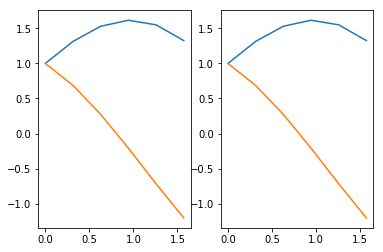

In [18]:
plt.subplot(1,2,1)
plt.plot(TPS,XEE)

X0 = [x[0] for x in XEE] 
print(len(X0))
Y0 = [x[1] for x in XEE]
plt.subplot(1,2,2)
plt.plot(TPS,X0, TPS, Y0)

#### Question 2. Lire les messages d'erreur
Une référence intéressante: http://interactivepython.org/runestone/static/thinkcspy/Debugging/KnowyourerrorMessages.html

Exemple 1: NameError

Executez le code ci-dessous et entrez des chiffres. Quelle est l'erreur?


In [ ]:
current_time_str = input("Quelle heure est-il (0-23h)?")
wait_time_str = input("Combien d'heures voulez-vous attendre?")

current_time_int = int(current_time_str)
wait_time_int = int(wait_time_int) 

final_time_int = current_time_int + wait_time_int
print(final_time_int)

A la ligne 5 le programmeur a utilisé la variable wait\_time\_int avant de la définir. En fait il voulait écrire

In [ ]:
wait_time_int = int(wait_time_str)

Exemple 2: ValueError

Executez le code ci-dessous. Quelle est l'erreur?


In [24]:
str_in1 = input("Quel est votre nom?")
str_in2 = input("Vous avez quel age?(chiffre)")
nameint = int(str_in1)
ageint = int(str_in2)



Quel est votre nom?marie
Vous avez quel age?(chiffre)3


ValueError: invalid literal for int() with base 10: 'marie'

A la ligne 3 le programmeur tente de convertir en entier une chaine de caractères. Impossible d'imaginer ce qu'il voulait en faire...

Exemple 3: SyntaxError

Executez le code ci-dessous. Quelle(s) est(sont) le(s) erreur(s)?

In [25]:
def mysum(x, y)
    total = x + y
    print(total)

SyntaxError: invalid syntax (<ipython-input-25-aa8d2215edc9>, line 1)

Le programmeur a oublié le caractère : à la fin de la ligne de déclaration de la fonction. Une autre erreur problable, cette fonction ne renvoie aucun résultat, peut-être qu'au lieu d'imprimer la somme, il faudrait la renvoyer comme résultat de la fonction

In [26]:
def mysum(x, y):
    total = x + y
    print(total)
    #ou mieux
    return total

Exemple 4: TypeError

Executez le code ci-dessous. Quelle est l'erreur? Quels sont les types des objets s et a?

In [27]:
a = 8
s = 'hello'
print(a+s)


TypeError: unsupported operand type(s) for +: 'int' and 'str'

Le programmeur a voulu imprimer les deux variables a et s. Mais a et s ne sont pas du meme type. Il fallait écrire:

print(str(a) + s) #la commande str(a) converti l'entier a=8 en string a='8'

ou bien:

print(a,s) #cette commande de python3 sait traiter l'impression de variables de différents types

Exemple 5: IndentationError

Executez les codes ci-dessous. Quelles sont les erreurs?

In [28]:
a = 3
 b = 4
print(a)

IndentationError: unexpected indent (<ipython-input-28-76d012d667b6>, line 2)

Le programmeur a indenté la ligne 2. En python, les indentations servent à définir des fonctions, de boucles, des if, etc...

Mettre une indentation qui ne sert a rien renvoie: IndentationError

De même, indenter des lignes après une commande 'for' fait que ces lignes seront executés dans la boucle.

In [29]:
for i in range(5):
i+=1
print(i)

IndentationError: expected an indented block (<ipython-input-29-751161e8f65c>, line 2)

Ici on a le problème contraire, le programmeur n'a pas indenté des lignes de la boucle. 

Exemple 6: des erreurs "emboîtées".

Executez la ligne suivante de la fonction EulerImplicite. Quelles lignes des messages d'erreur nous apportent des informations utiles?

Indice: on commence toujours par la derniere ligne (ou groupe de lignes). En remontant dans les messages d'erreur, si les autres messages mentionnent du code que nous n'avons pas écrit, cela veut dire qu'il nous cite des lignes de code des librairies python. Alors on lit la premiere ligne (ou groupe de lignes). Les flèches indiquent les lignes de code où se trouve l'erreur. 

In [30]:
x_n1=scipy.optimize.fsolve(g,XEE[-1],XEE[-1],TPS[-1],dt,f )

TypeError: g() missing 3 required positional arguments: 't', 'h', and 'f'

La dernière ligne de l'erreur est: TypeError: g() missing 3 required positional arguments: 't', 'f', and 'h'

Ceci nous indique qu'il y a un problème avec le nombre d'arguments. En remontant le message d'erreur, on ne reconnait pas le code. 

Donc on remonte à la première ligne: TypeError       

----> 1 x_n1=scipy.optimize.fsolve(g,XEE[-1],XEE[-1],TPS[-1],dt,f )

Ici on reconnait notre code. C'est donc un problème dans les arguments passés à scipy. 
Rappel: si la fonction g prend N>2 arguments, il faut passer les 2:N arguments dans un tableau.

Il faut donc écrire:


In [ ]:
args_g=1.,1,f,0.1 #valeurs choicies au hasard pour l'exemple 
x_n1=scipy.optimize.fsolve(g,2.,args=args_g)

Exemple 7: un exemple plus astucieux. 

Executez le code ci-dessous. Quelle et l'erreur? Pourquoi n'a-t-on pas des valeurs compatibles entre t_ et EulerExplicite3? 

Indice: quels sont les types de t_ et EulerExplicite3?

In [ ]:
t_=np.linspace(0,5.,50)
plt.plot(t_,EulerExplicite3)

La dernière ligne de l'erreur est: ValueError: x and y must have same first dimension, but have shapes (50,) and (1,)

Ceci nous indique qu'il y a un problème de dimension entre t\_ et EulerExplicite3, qui doivent être de la même dimension. En remontant le message d'erreur, on ne reconnait pas le code. 

Donc on remonte à la première ligne:        

----> 2 plt.plot(t\_,EulerExplicite3)

Ici on reconnait notre code, et on confirme que le problème est que t\_ et EulerExplicite3 ne sont pas des variables compatibles. 
Mais c'est normal, EulerExplicite3 n'est ni liste ni tableau, il s'agit d'une fonction!

Il faut donc écrire:

X,TPS = EulerExplicite3(...les arguments...)

plt.plot(TPS,X)